In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

In [3]:
df = pd.read_csv("/Users/marisa/Desktop/Data Analytics/Week12/lab-eda-univariate/amz_uk_price_prediction_dataset.csv")

In [4]:
df.head()
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


,uid,stars,reviews,price,boughtInLastMonth
count,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06,2.443651e+06
mean,1.370545e+06,2.152836e+00,4.806278e+02,8.924381e+01,2.589699e+01
std,8.160562e+05,2.194865e+00,5.944124e+03,3.456089e+02,2.404837e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,6.589215e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349029e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060686e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


In [5]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

# Understanding Product Categories

In [10]:
# frequency table
category_counts = df["category"].value_counts()
category_counts.head(10)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64

In [ ]:
# top 5 categories
top5_categories = category_counts.head(5)
top5_categories

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

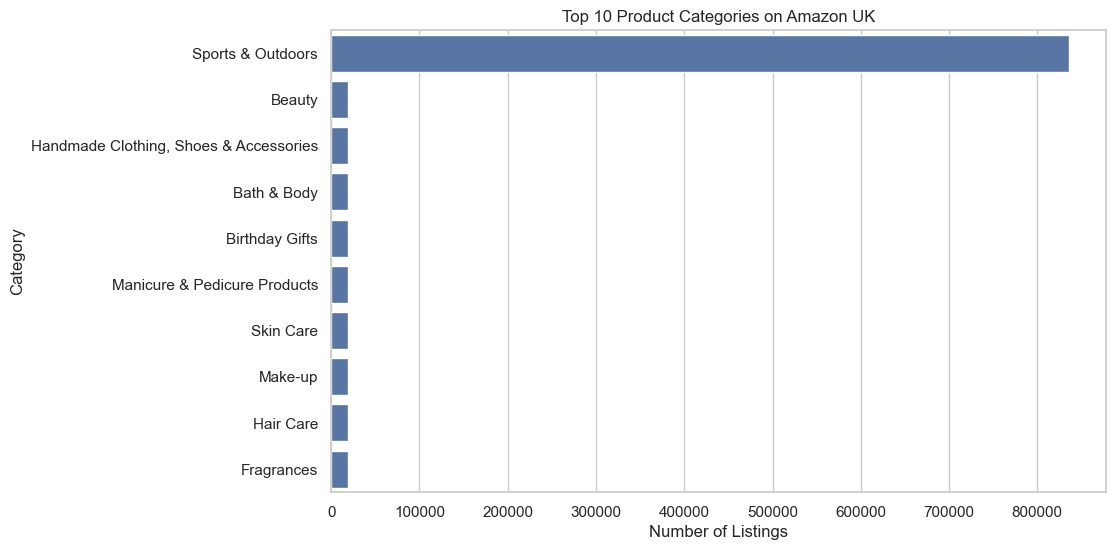

In [11]:
# bar chart
plt.figure(figsize=(10,6))

sns.barplot(
    x=category_counts.head(10).values,
    y=category_counts.head(10).index
)

plt.title("Top 10 Product Categories on Amazon UK")
plt.xlabel("Number of Listings")
plt.ylabel("Category")

plt.show()

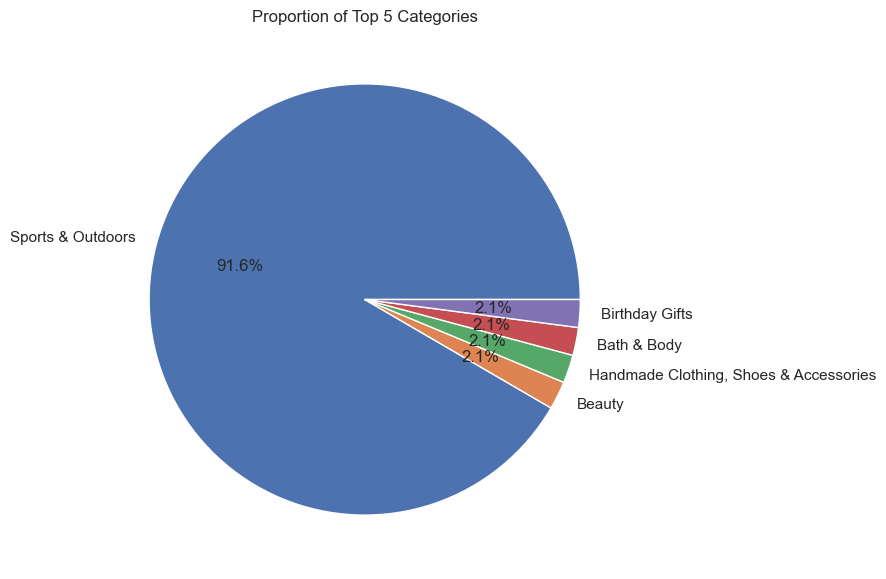

In [12]:
# pie chart
plt.figure(figsize=(7,7))

top5_categories.plot(
    kind="pie",
    autopct='%1.1f%%'
)

plt.title("Proportion of Top 5 Categories")
plt.ylabel("")

plt.show()

The distribution of product listings across categories is highly concentrated. The Sports & Outdoors category dominates the dataset, accounting for approximately 91.6% of all listings, while the remaining categories (Beauty, Handmade Clothing, Bath & Body, and Birthday Gifts) each represent only about 2.1% of listings. This strong imbalance suggests that the dataset is heavily focused on Sports & Outdoors products, which may reflect higher demand, stronger seller competition, or a sampling bias in the dataset. For businesses, this indicates that competition in this category is likely intense, while smaller categories may represent potential niche opportunities with less saturation.

# Product Pricing

In [13]:
# measures of centrality
mean_price = df["price"].mean()
median_price = df["price"].median()
mode_price = df["price"].mode()[0]

print("Mean:", mean_price)
print("Median:", median_price)
print("Mode:", mode_price)

Mean: 89.24380943923663
Median: 19.09
Mode: 9.99


The average product price is 89.24, while the median price is much lower at 19.09, and the most common price point (mode) is 9.99. The large gap between the mean and median indicates that the price distribution is highly right-skewed, meaning that a small number of very expensive products significantly increase the average price. Most products on Amazon UK appear to be priced at relatively affordable levels, with many clustered around the 10–£20 range.

In [14]:
# measures of dispersion
price_variance = df["price"].var()
price_std = df["price"].std()
price_range = df["price"].max() - df["price"].min()
price_iqr = df["price"].quantile(0.75) - df["price"].quantile(0.25)

print("Variance:", price_variance)
print("Std Dev:", price_std)
print("Range:", price_range)
print("IQR:", price_iqr)

Variance: 119445.4853225653
Std Dev: 345.6088617535223
Range: 100000.0
IQR: 36.0


The dispersion metrics reveal a very large spread in product prices. The range of £100,000 suggests that while most products are inexpensive, there are extremely high-priced items in the dataset. The high standard deviation further confirms significant variability in pricing. However, the interquartile range (IQR) of 36 indicates that the middle 50% of product prices are relatively concentrated within a much smaller price band. This suggests that the majority of products are priced within a moderate range, while a small number of luxury or specialized items create extreme outliers.

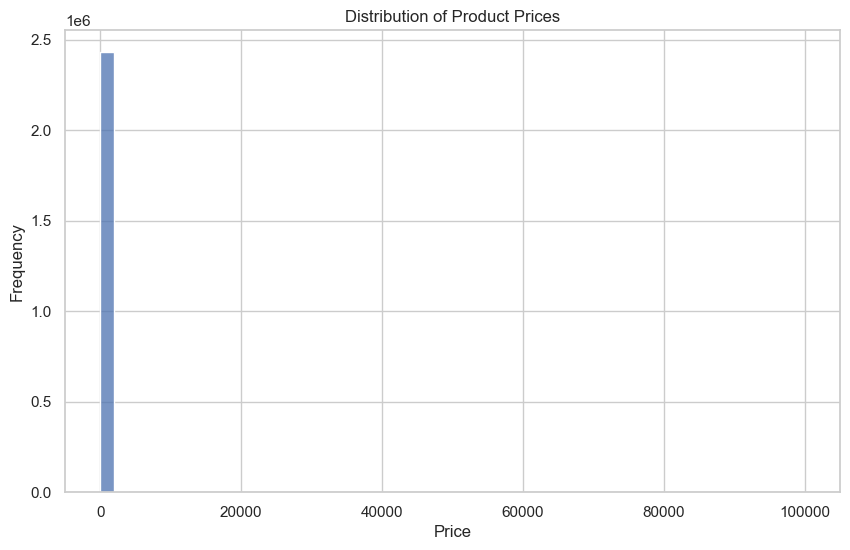

In [15]:
# histogram of price
plt.figure(figsize=(10,6))

sns.histplot(df["price"], bins=50)

plt.title("Distribution of Product Prices")
plt.xlabel("Price")
plt.ylabel("Frequency")

plt.show()

The histogram shows that the majority of products are priced at relatively low values, with a strong concentration near the lower end of the price scale. However, the presence of extremely expensive products stretches the distribution up to 100,000, compressing most observations into a small area on the chart. This makes the distribution difficult to interpret visually. Applying a logarithmic scale or filtering extreme outliers would make the distribution clearer.

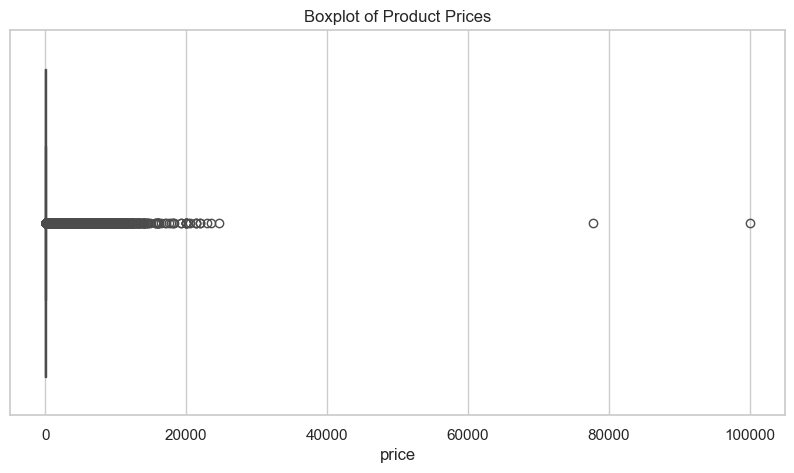

In [16]:
# boxplot
plt.figure(figsize=(10,5))
sns.boxplot(x=df["price"])
plt.title("Boxplot of Product Prices")
plt.show()

Overall, the pricing structure of Amazon UK products is heavily skewed toward lower price points, with most products priced below 20. However, a small number of premium or specialized items with very high prices significantly increase the overall average and create extreme outliers in the distribution. For sellers, this suggests that the marketplace is largely competitive in lower price segments, while high-price products likely belong to niche categories or luxury items.

# Product rating 

In [18]:
# centrality
mean_rating = df["stars"].mean()
median_rating = df["stars"].median()
mode_rating = df["stars"].mode()[0]

print("Mean:", mean_rating)
print("Median:", median_rating)
print("Mode:", mode_rating)

Mean: 2.152836472966065
Median: 0.0
Mode: 0.0


The average product rating is 2.15, while both the median and mode are 0, indicating that a large number of products in the dataset have no rating recorded. This suggests that many products either have not yet received customer reviews or their ratings are missing. As a result, the average rating is pulled down significantly by the high number of zero values, making the mean less representative of actual customer satisfaction levels.

In [22]:
# dispersion
rating_variance = df["stars"].var()
rating_std = df["stars"].std()
rating_iqr = df["stars"].quantile(0.75) - df["stars"].quantile(0.25)

print("Variance:", rating_variance)
print("Std Dev:", rating_std)
print("IQR:", rating_iqr)

Variance: 4.81743402976196
Std Dev: 2.1948653785054697
IQR: 4.4


The relatively high standard deviation and interquartile range indicate a wide spread in rating values, ranging from 0 to 5 stars. This spread is largely influenced by the presence of many zero ratings combined with a cluster of higher ratings near the upper end of the scale. This suggests that while many products have no ratings, those that do tend to receive relatively high scores.

In [23]:
# shape of distribution
skewness = df["stars"].skew()
kurtosis = df["stars"].kurt()

print("Skewness:", skewness)
print("Kurtosis:", kurtosis)

Skewness: 0.08120735761080985
Kurtosis: -1.9260061280432985


The skewness value close to zero (0.08) suggests that the distribution is roughly symmetrical overall. However, the histogram reveals two distinct clusters: one at 0 stars and another between 4 and 5 stars. The negative kurtosis indicates a flatter distribution with lighter tails than a normal distribution, meaning ratings are spread across the range rather than being highly concentrated around the mean.

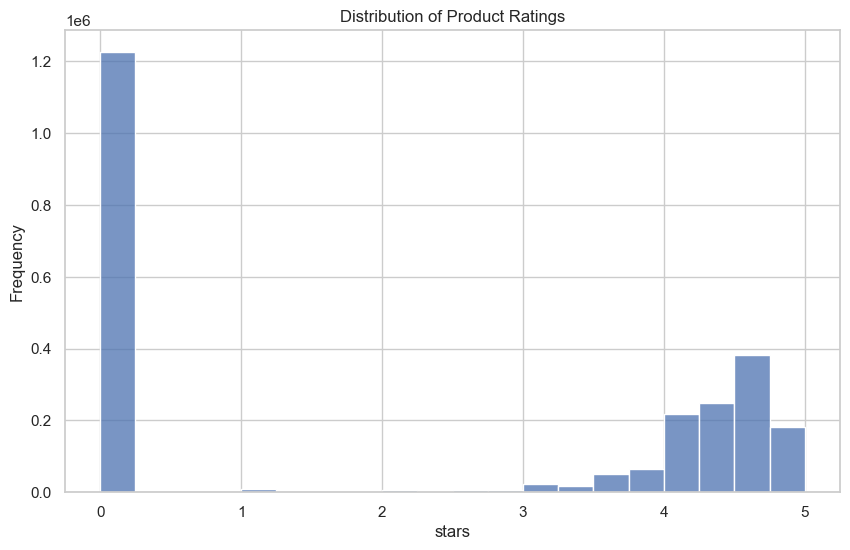

In [21]:
plt.figure(figsize=(10,6))

sns.histplot(df["stars"], bins=20)

plt.title("Distribution of Product Ratings")
plt.xlabel("stars")
plt.ylabel("Frequency")

plt.show()

The distribution of product ratings shows two dominant clusters: a large number of products with 0 stars, likely representing items without reviews, and another concentration between 4 and 5 stars, indicating that products with reviews generally receive positive feedback. This pattern suggests that customer-rated products tend to perform well, while many listings simply lack rating data.

# Business-centric report summary

The exploratory analysis of Amazon UK product listings reveals several important patterns in category distribution, pricing, and customer ratings. Product listings are heavily concentrated in the Sports & Outdoors category, which accounts for the vast majority of listings, indicating strong competition within this segment. Pricing analysis shows a highly right-skewed distribution, where most products are relatively inexpensive, often below 20, while a small number of premium items reach extremely high prices and significantly increase the average price. Customer ratings show a bimodal pattern, with many products lacking ratings while those with reviews tend to receive high scores between 4 and 5 stars. Overall, these findings suggest that the Amazon UK marketplace is dominated by a few major product categories, competitive low-price products, and generally positive customer feedback for items that receive reviews.